## Prepare Data



In [87]:
import tensorflow as tf
import numpy as np

seed = 42

np.random.seed(seed)
tf.random.set_seed(seed)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training data:", x_train.shape)
print("Test data:", x_test.shape)


Training data: (50000, 32, 32, 3)
Test data: (10000, 32, 32, 3)


### small traing data

In [88]:
x_small=[]
y_small=[]
for i in range(10):
    count=0
    for j in range(len(y_train)):
        if y_train[j][0]==i and count<50:
            x_small.append(x_train[j])
            y_small.append(y_train[j])
            count=count+1
x_small=np.array(x_small)
y_small=np.array(y_small)
print("Small training data:", x_small.shape)
print("Small training labels:", y_small.shape)

Small training data: (500, 32, 32, 3)
Small training labels: (500, 1)


In [89]:
for i in range(10):
    count=0
    for j in range(len(y_small)):
        if y_small[j][0]==i:
            count=count+1
    print("Class", i, ":", count)

Class 0 : 50
Class 1 : 50
Class 2 : 50
Class 3 : 50
Class 4 : 50
Class 5 : 50
Class 6 : 50
Class 7 : 50
Class 8 : 50
Class 9 : 50


### Traing and Validation

In [90]:
x_train_small=[]
y_train_small=[]
x_val=[]
y_val=[]
for i in range(10):
    count=0
    for j in range(len(y_small)):
        if y_small[j][0]==i:
            if count<40:
                x_train_small.append(x_small[j])
                y_train_small.append(y_small[j])
            else:
                x_val.append(x_small[j])
                y_val.append(y_small[j])
            count=count+1
x_train_small=np.array(x_train_small)
y_train_small=np.array(y_train_small)
x_val=np.array(x_val)
y_val=np.array(y_val)
print("Training:", x_train_small.shape)
print("Training labels:", y_train_small.shape)
print("Validation:", x_val.shape)
print("Validation labels:", y_val.shape)

Training: (400, 32, 32, 3)
Training labels: (400, 1)
Validation: (100, 32, 32, 3)
Validation labels: (100, 1)


### Clean test

In [91]:
x_clean_test=x_test
y_clean_test=y_test
print("Clean test:", x_clean_test.shape)
print("Clean test labels:", y_clean_test.shape)

Clean test: (10000, 32, 32, 3)
Clean test labels: (10000, 1)


In [92]:
x_train_small=x_train_small.astype("float32")/255.0
x_val=x_val.astype("float32")/255.0
x_clean_test=x_clean_test.astype("float32")/255.0

print("Training range:", x_train_small.min(), x_train_small.max())
print("Validation range:", x_val.min(), x_val.max())
print("Clean test range:", x_clean_test.min(), x_clean_test.max())

Training range: 0.0 1.0
Validation range: 0.0 1.0
Clean test range: 0.0 1.0


### Shifted test

random rotation upto +-25

In [93]:
x_shifted_test=x_test.astype("float32")/255.0
rotate=tf.keras.layers.RandomRotation(factor=25/360, seed=42)
x_shifted_test=rotate(x_shifted_test, training=True)
print("Shifted test:", x_shifted_test.shape)

Shifted test: (10000, 32, 32, 3)


brightness and contrast

In [94]:
x_shifted_test=tf.image.random_brightness(x_shifted_test, max_delta=0.05, seed=42)
x_shifted_test=tf.image.random_contrast(x_shifted_test, lower=0.95, upper=1.05, seed=42)
x_shifted_test=tf.clip_by_value(x_shifted_test, 0.0, 1.0)

random rectangular occlusion

In [95]:
x_shifted_test=x_shifted_test.numpy()
for i in range(len(x_shifted_test)):
    x=np.random.randint(0,17)
    y=np.random.randint(0,17)
    x_shifted_test[i,x:x+16,y:y+16,:]=0.0
print("Shifted test:", x_shifted_test.shape)

Shifted test: (10000, 32, 32, 3)


random greyscale

In [96]:
for i in range(len(x_shifted_test)):
    if np.random.rand()<0.2:
        x_shifted_test[i]=np.repeat(np.mean(x_shifted_test[i],axis=2,keepdims=True),3,axis=2)
print("Shifted test:", x_shifted_test.shape)

Shifted test: (10000, 32, 32, 3)


In [97]:
print("Shifted test:", x_shifted_test.shape)
print("Minimum value:", x_shifted_test.min())
print("Maximum value:", x_shifted_test.max())

Shifted test: (10000, 32, 32, 3)
Minimum value: 0.0
Maximum value: 0.99115


# Tasks

## Part A

In [98]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense, Dropout, Concatenate

In [99]:

print("Training:", x_train_small.shape)
print("Validation:", x_val.shape)

Training: (400, 32, 32, 3)
Validation: (100, 32, 32, 3)


In [100]:
from tensorflow.keras.models import Model

from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Concatenate
inputs=Input(shape=(32,32,3))
x=Conv2D(16,(3,3),activation="relu",padding="same")(inputs)
b1=Conv2D(8,(1,1),activation="relu",padding="same")(x)
b2=Conv2D(8,(1,1),activation="relu",padding="same")(x)
b2=Conv2D(8,(3,3),activation="relu",padding="same")(b2)
b3=Conv2D(8,(1,1),activation="relu",padding="same")(x)
b3=Conv2D(8,(5,5),activation="relu",padding="same")(b3)
x=Concatenate()([b1,b2,b3])
x=MaxPooling2D((2,2))(x)
x=Conv2D(16,(3,3),activation="relu",padding="same")(x)

x=MaxPooling2D((2,2))(x)
x=Flatten()(x)
outputs=Dense(10,activation="softmax")(x)
model=Model(inputs,outputs)
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │        448 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32, 8) │        136 │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32, 8) │        136 │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32, 8) │        136 │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32, 8) │        584 │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 32, 32, 8) │      1,608 │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ conv2d_8[0][0],   │
│ (Concatenate)       │ 24)               │            │ conv2d_10[0][0],  │
│                     │                   │            │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ concatenate_1[0]… │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │      3,472 │ max_pooling2d_2[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 16)  │          0 │ conv2d_13[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1024)      │          0 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │     10,250 │ flatten_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,770 (65.51 KB)

 Trainable params: 16,770 (65.51 KB)

 Non-trainable params: 0 (0.00 B)

In [101]:
history = model.fit(
    x_train_small, y_train_small,
    batch_size=32,
    epochs=60,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 365ms/step - accuracy: 0.1025 - loss: 2.3198 - val_accuracy: 0.1200 - val_loss: 2.2844
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1525 - loss: 2.2491 - val_accuracy: 0.1800 - val_loss: 2.2529
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2175 - loss: 2.1778 - val_accuracy: 0.2300 - val_loss: 2.1805
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2650 - loss: 2.0562 - val_accuracy: 0.2100 - val_loss: 2.1558
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3125 - loss: 1.9409 - val_accuracy: 0.2100 - val_loss: 2.0693
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3375 - loss: 1.8209 - val_accuracy: 0.2400 - val_loss: 2.0448
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3750 - loss: 1.7102 - val_accuracy: 0.2600 - val_loss: 2.0308
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4400 - loss: 1.5984 - val_accuracy: 0.2700 - 

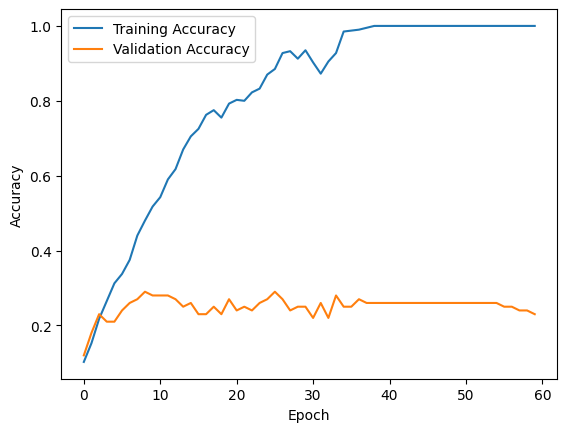

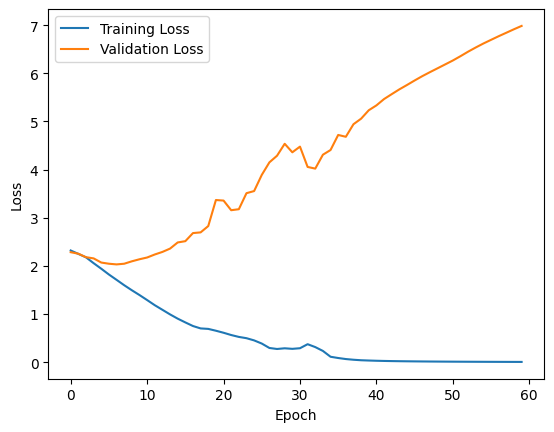

In [102]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [103]:
train_loss,train_acc=model.evaluate(x_train_small,y_train_small,verbose=0)
val_loss,val_acc=model.evaluate(x_val,y_val,verbose=0)
clean_loss,clean_acc=model.evaluate(x_clean_test,y_clean_test,verbose=0)
shift_loss,shift_acc=model.evaluate(x_shifted_test,y_test,verbose=0)

print("Training Accuracy:",train_acc)
print("Validation Accuracy:",val_acc)
print("Clean Test Accuracy:",clean_acc)
print("Shifted Test Accuracy:",shift_acc)

Training Accuracy: 1.0
Validation Accuracy: 0.23000000417232513
Clean Test Accuracy: 0.30820000171661377
Shifted Test Accuracy: 0.17829999327659607


The model achieved 100% training accuracy but only 23% validation accuracy, indicating significant overfitting. Its clean-test accuracy was 30.8%, which decreased to 17.8% on the shifted test set. The shifted images contain rotation, brightness and contrast changes, rectangular occlusion, and grayscale transformations, which make classification more challenging. These results indicate that the model memorizes the small training dataset and struggles to generalize to unseen and distribution-shifted images.

# Part B

In [71]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    RandomFlip, RandomRotation, RandomTranslation,
    RandomBrightness, RandomContrast
)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Concatenate
)

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.05),
    RandomTranslation(0.08, 0.08),
    RandomBrightness(0.08, value_range=(0, 1)),
    RandomContrast(0.08)
])

seeds = [42, 123, 456]
results_b = []

In [72]:
for seed in seeds:

    print("\nSeed:", seed)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )

    train_data = train_data.shuffle(
        400, seed=seed
    ).batch(32)

    train_data = train_data.map(
        lambda x, y: (data_augmentation(x, training=True), y)
    )

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])

    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)

    x = Flatten()(x)
    outputs = Dense(10,activation="softmax")(x)

    model_b = Model(inputs,outputs)

    model_b.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_b = model_b.fit(
        train_data,
        epochs=60,
        validation_data=(x_val, y_val),
        verbose=1
    )

    train_loss, train_acc = model_b.evaluate(
        x_train_small, y_train_small, verbose=0
    )

    val_loss, val_acc = model_b.evaluate(
        x_val, y_val, verbose=0
    )

    clean_loss, clean_acc = model_b.evaluate(
        x_clean_test, y_clean_test, verbose=0
    )

    shift_loss, shift_acc = model_b.evaluate(
        x_shifted_test, y_test, verbose=0
    )

    results_b.append([train_acc, val_acc, clean_acc, shift_acc])

    print("Training Accuracy:", train_acc)
    print("Validation Accuracy:", val_acc)
    print("Clean Test Accuracy:", clean_acc)
    print("Shifted Test Accuracy:", shift_acc)


Seed: 42
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 504ms/step - accuracy: 0.0800 - loss: 2.3120 - val_accuracy: 0.1100 - val_loss: 2.2967
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1425 - loss: 2.2919 - val_accuracy: 0.1800 - val_loss: 2.2773
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1550 - loss: 2.2650 - val_accuracy: 0.1700 - val_loss: 2.2360
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.2400 - loss: 2.1720 - val_accuracy: 0.2000 - val_loss: 2.1377
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2725 - loss: 2.0202 - val_accuracy: 0.1800 - val_loss: 2.2458
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2750 - loss: 2.0160 - val_accuracy: 0.1700 - val_loss: 2.0454
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3075 - loss: 1.9107 - val_accuracy: 0.2600 - val_loss: 2.0441
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3750 - loss: 1.8346 - val_accuracy

In [73]:
results_b = np.array(results_b)

print("Mean Accuracy:")
print("Training:", results_b[:,0].mean())
print("Validation:", results_b[:,1].mean())
print("Clean Test:", results_b[:,2].mean())
print("Shifted Test:", results_b[:,3].mean())

print("\nStandard Deviation:")
print("Training:", results_b[:,0].std(ddof=1))
print("Validation:", results_b[:,1].std(ddof=1))
print("Clean Test:", results_b[:,2].std(ddof=1))
print("Shifted Test:", results_b[:,3].std(ddof=1))

Mean Accuracy:
Training: 0.7433333396911621
Validation: 0.3399999936421712
Clean Test: 0.42576666673024494
Shifted Test: 0.24936666587988535

Standard Deviation:
Training: 0.0062915226959896296
Validation: 0.034641017527887855
Clean Test: 0.008972361855103179
Shifted Test: 0.006206717261953727


**1. Would vertical flip help or hurt on this dataset? Why?**

Vertical flipping may hurt performance on CIFAR-10 because flipping images upside down can create unrealistic views of objects such as cars, trucks, and ships. Horizontal flipping is generally more suitable because these objects can still look realistic when viewed from the opposite side.

**2. If rotation up to ±90° is used but the test only has ±25°, what is the trade-off?**

Rotation up to ±90° introduces greater variation and may help the model recognize objects in different orientations. However, the test images contain rotations of only ±25°, so larger rotations may create unrealistic training examples. This can make learning harder and reduce accuracy on the test set. Small rotations closer to the expected test variations may work better.

**3. Why can too much augmentation reduce accuracy on such a small model?**

Excessive augmentation can make training images too different from realistic test images, making useful features harder to learn. A small model has limited capacity, and the combination of many transformations can make learning more difficult. Since the training dataset contains only 400 images, moderate and realistic augmentation is preferable to overly aggressive transformations.

# Part C

In [74]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

seeds = [42, 123, 456]
results_c = []

for seed in seeds:
    print("\nSeed:", seed)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    inputs = Input(shape=(32, 32, 3))

    x = Conv2D(
        16, (3, 3), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(inputs)

    b1 = Conv2D(
        8, (1, 1), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(x)

    b2 = Conv2D(
        8, (1, 1), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(x)
    b2 = Conv2D(
        8, (3, 3), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(b2)

    b3 = Conv2D(
        8, (1, 1), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(x)
    b3 = Conv2D(
        8, (5, 5), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(b3)

    x = Concatenate()([b1, b2, b3])
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(
        16, (3, 3), activation="relu", padding="same",
        kernel_regularizer=l2(0.00001)
    )(x)

    x = MaxPooling2D((2, 2))(x)
    x = Flatten()(x)
    x = Dropout(0.25)(x)

    outputs = Dense(10, activation="softmax")(x)

    model_c = Model(inputs, outputs)

    model_c.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )

    lr_schedule = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=0.000001,
        verbose=1
    )

    history_c = model_c.fit(
        train_data,
        epochs=60,
        validation_data=(x_val, y_val),
        callbacks=[early_stop, lr_schedule],
        verbose=1
    )

    train_loss, train_acc = model_c.evaluate(
        x_train_small, y_train_small, verbose=0
    )

    val_loss, val_acc = model_c.evaluate(
        x_val, y_val, verbose=0
    )

    clean_loss, clean_acc = model_c.evaluate(
        x_clean_test, y_clean_test, verbose=0
    )

    shift_loss, shift_acc = model_c.evaluate(
        x_shifted_test, y_test, verbose=0
    )

    results_c.append([
        train_acc, val_acc, clean_acc, shift_acc
    ])

    print("Training Accuracy:", train_acc)
    print("Validation Accuracy:", val_acc)
    print("Clean Test Accuracy:", clean_acc)
    print("Shifted Test Accuracy:", shift_acc)


Seed: 42
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 355ms/step - accuracy: 0.0725 - loss: 2.3063 - val_accuracy: 0.0700 - val_loss: 2.3011 - learning_rate: 0.0010
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.0950 - loss: 2.2953 - val_accuracy: 0.1100 - val_loss: 2.2877 - learning_rate: 0.0010
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1675 - loss: 2.2661 - val_accuracy: 0.1400 - val_loss: 2.2647 - learning_rate: 0.0010
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1950 - loss: 2.2039 - val_accuracy: 0.2100 - val_loss: 2.1608 - learning_rate: 0.0010
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2350 - loss: 2.0552 - val_accuracy: 0.2100 - val_loss: 2.0769 - learning_rate: 0.0010
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2875 - loss: 1.9753 - val_accuracy: 0.2400 - val_loss: 2.0366 - learning_rate: 0.0010
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.2975 - loss: 1.92

In [75]:
results_c = np.array(results_c)

print("Mean Results:")
print("Training Accuracy:", np.mean(results_c[:, 0]))
print("Validation Accuracy:", np.mean(results_c[:, 1]))
print("Clean Test Accuracy:", np.mean(results_c[:, 2]))
print("Shifted Test Accuracy:", np.mean(results_c[:, 3]))

print("\nStandard Deviation:")
print("Training Accuracy:", np.std(results_c[:, 0]))
print("Validation Accuracy:", np.std(results_c[:, 1]))
print("Clean Test Accuracy:", np.std(results_c[:, 2]))
print("Shifted Test Accuracy:", np.std(results_c[:, 3]))

Mean Results:
Training Accuracy: 0.5600000023841858
Validation Accuracy: 0.3199999928474426
Clean Test Accuracy: 0.3944000005722046
Shifted Test Accuracy: 0.23599999646345773

Standard Deviation:
Training Accuracy: 0.0147195874061739
Validation Accuracy: 0.024494898401171552
Clean Test Accuracy: 0.006576215242029485
Shifted Test Accuracy: 0.009142209548936823


L2 Regularization: L2 is added to convolutional layers to keep their weights small and prevent the model from overfitting to training images.

Dropout: Dropout is placed after the Flatten layer and before the final Dense layer because the features have already been extracted from the images. It prevents the model from depending too much on specific features. It is not placed between early convolutional layers because this may disturb the learning of important image features.

EarlyStopping: EarlyStopping monitors validation loss during training. It stops training when the validation loss does not improve for 12 epochs and restores the weights from the best epoch to avoid unnecessary training.

ReduceLROnPlateau: This callback monitors validation loss and reduces the learning rate when it does not improve for 6 epochs. It helps the model make smaller updates when learning slows down.

Data Augmentation and Occlusion: These are applied to training data before it enters the model. This helps the model learn from different image variations. They are not applied to validation and test data because these images must remain unchanged for fair evaluation.

# Part D

# No Augmentation

In [50]:
seeds = [42, 123, 456]
results = []

for seed in seeds:
    tf.keras.utils.set_random_seed(seed)

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)

    model = Model(inputs,outputs)

    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    model.fit(x_train_small, y_train_small,
              epochs=60, batch_size=32,
              validation_data=(x_val,y_val), verbose=0)

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc, clean_acc, shift_acc])

    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))

42 0.33000001311302185 0.3352999985218048 0.1876000016927719
123 0.25 0.3416999876499176 0.19339999556541443
456 0.27000001072883606 0.33899998664855957 0.19130000472068787
Mean: [0.28333334 0.33866666 0.19076667]
Std: [0.04163333 0.00321299 0.00293655]


Geometeric

In [80]:
seeds = [42, 123, 456]
results = []

for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(factor=25/360, seed=42)
    ])

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )
    train_data = train_data.shuffle(400, seed=seed).batch(32)
    train_data = train_data.map(
        lambda x, y: (data_augmentation(x, training=True), y)
    )

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val,y_val),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc,clean_acc,shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.3400000035762787 0.38420000672340393 0.19259999692440033
123 0.3199999928474426 0.38449999690055847 0.18320000171661377
456 0.33000001311302185 0.4011000096797943 0.22450000047683716
Mean: [0.33       0.38993334 0.2001    ]
Std: [0.01000001 0.00967178 0.0216474 ]


Photometric only

In [81]:
seeds = [42, 123, 456]
results = []

def photometric_augmentation(images):
    images = tf.image.random_brightness(
        images, max_delta=0.05, seed=42
    )
    images = tf.image.random_contrast(
        images, lower=0.95, upper=1.05, seed=42
    )
    return tf.clip_by_value(images, 0.0, 1.0)

for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )
    train_data = train_data.shuffle(400, seed=seed).batch(32)
    train_data = train_data.map(
        lambda x, y: (photometric_augmentation(x), y)
    )

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val,y_val),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc,clean_acc,shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.2800000011920929 0.34630000591278076 0.19789999723434448
123 0.20999999344348907 0.3441999852657318 0.19850000739097595
456 0.3100000023841858 0.3456000089645386 0.19130000472068787
Mean: [0.26666667 0.34536667 0.1959    ]
Std: [0.05131602 0.00106928 0.003995  ]


Geometric + photometric

In [82]:
seeds = [42, 123, 456]
results = []

def photometric_augmentation(images):
    images = tf.image.random_brightness(
        images, max_delta=0.05, seed=42
    )
    images = tf.image.random_contrast(
        images, lower=0.95, upper=1.05, seed=42
    )
    return tf.clip_by_value(images, 0.0, 1.0)

for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    geometric_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(factor=25/360, seed=42)
    ])

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )
    train_data = train_data.shuffle(400, seed=seed).batch(32)

    train_data = train_data.map(
        lambda x, y: (
            photometric_augmentation(
                geometric_augmentation(x, training=True)
            ),
            y
        )
    )

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val,y_val),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc,clean_acc,shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.36000001430511475 0.3912000060081482 0.20749999582767487
123 0.33000001311302185 0.3828999996185303 0.1995999962091446
456 0.33000001311302185 0.3928000032901764 0.22679999470710754
Mean: [0.34000001 0.38896667 0.2113    ]
Std: [0.01732051 0.00531445 0.0139925 ]


Geometric + photometric+ Cutout / Random Erasing

In [83]:
seeds = [42, 123, 456]
results = []

def photometric_augmentation(images):
    images = tf.image.random_brightness(
        images, max_delta=0.05, seed=42
    )
    images = tf.image.random_contrast(
        images, lower=0.95, upper=1.05, seed=42
    )
    return tf.clip_by_value(images, 0.0, 1.0)


def add_occlusion(images, labels):
    batch_size = tf.shape(images)[0]

    for i in tf.range(batch_size):
        x = tf.random.uniform([], 0, 17, dtype=tf.int32)
        y = tf.random.uniform([], 0, 17, dtype=tf.int32)

        rows = tf.range(32)[:, None]
        cols = tf.range(32)[None, :]

        mask = tf.cast(
            (rows >= x) & (rows < x + 16) &
            (cols >= y) & (cols < y + 16),
            tf.float32
        )

        image = images[i] * (1 - mask[:, :, None])

        images = tf.tensor_scatter_nd_update(
            images, [[i]], [image]
        )

    return images, labels


for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    geometric_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(factor=25/360, seed=42)
    ])

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )
    train_data = train_data.shuffle(400, seed=seed).batch(32)

    train_data = train_data.map(
        lambda x, y: (
            photometric_augmentation(
                geometric_augmentation(x, training=True)
            ),
            y
        )
    )

    train_data = train_data.map(add_occlusion)

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val,y_val),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc,clean_acc,shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.3100000023841858 0.3804999887943268 0.3240000009536743
123 0.3100000023841858 0.3937000036239624 0.3260999917984009
456 0.33000001311302185 0.3790999948978424 0.32670000195503235
Mean: [0.31666667 0.38443333 0.3256    ]
Std: [0.01154701 0.00805565 0.00141774]


Geometric + photometric+Mixup or CutMix + label smoothing

In [86]:
seeds = [42, 123, 456]
results = []

def photometric_augmentation(images):
    images = tf.image.random_brightness(
        images, max_delta=0.05, seed=42
    )
    images = tf.image.random_contrast(
        images, lower=0.95, upper=1.05, seed=42
    )
    return tf.clip_by_value(images, 0.0, 1.0)


def cutmix(images, labels):
    batch_size = tf.shape(images)[0]
    labels = tf.reshape(labels, [-1])

    indices = tf.random.shuffle(tf.range(batch_size))
    images2 = tf.gather(images, indices)
    labels2 = tf.gather(labels, indices)

    lam = tf.random.uniform([], 0.3, 0.7)

    cut_size = tf.cast(32 * tf.sqrt(1.0 - lam), tf.int32)
    cut_size = tf.minimum(cut_size, 32)

    x = tf.random.uniform([], 0, 33 - cut_size, dtype=tf.int32)
    y = tf.random.uniform([], 0, 33 - cut_size, dtype=tf.int32)

    rows = tf.range(32)[:, None]
    cols = tf.range(32)[None, :]

    mask = tf.cast(
        (rows >= x) & (rows < x + cut_size) &
        (cols >= y) & (cols < y + cut_size),
        tf.float32
    )

    images = images * (1 - mask[None, :, :, None]) + \
             images2 * mask[None, :, :, None]

    area = tf.reduce_mean(mask)

    labels = tf.one_hot(tf.cast(labels, tf.int32), depth=10)
    labels2 = tf.one_hot(tf.cast(labels2, tf.int32), depth=10)

    labels = labels * (1 - area) + labels2 * area

    return images, labels


for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    geometric_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(factor=25/360, seed=42)
    ])

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )

    train_data = train_data.shuffle(400, seed=seed).batch(32)

    train_data = train_data.map(
        lambda x, y: (
            photometric_augmentation(
                geometric_augmentation(x, training=True)
            ),
            y
        )
    )

    train_data = train_data.map(cutmix)

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.CategoricalCrossentropy(
            label_smoothing=0.1
        ),
        metrics=["accuracy"]
    )

    y_val_onehot = tf.one_hot(
        tf.cast(tf.reshape(y_val, [-1]), tf.int32), depth=10
    )

    y_clean_onehot = tf.one_hot(
        tf.cast(tf.reshape(y_clean_test, [-1]), tf.int32), depth=10
    )

    y_test_onehot = tf.one_hot(
        tf.cast(tf.reshape(y_test, [-1]), tf.int32), depth=10
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val, y_val_onehot),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val, y_val_onehot, verbose=0)
    _, clean_acc = model.evaluate(x_clean_test, y_clean_onehot, verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test, y_test_onehot, verbose=0)

    results.append([val_acc, clean_acc, shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.3199999928474426 0.39079999923706055 0.27410000562667847
123 0.3700000047683716 0.38580000400543213 0.26030001044273376
456 0.3100000023841858 0.3952000141143799 0.25769999623298645
Mean: [0.33333333 0.39060001 0.26403334]
Std: [0.03214551 0.0047032  0.00881438]


Final model

Geometric + photometric+ Cutout

In [108]:
seeds = [42, 123, 456]
results = []

def photometric_augmentation(images):
    images = tf.image.random_brightness(
        images, max_delta=0.05, seed=42
    )
    images = tf.image.random_contrast(
        images, lower=0.95, upper=1.05, seed=42
    )
    return tf.clip_by_value(images, 0.0, 1.0)


def add_occlusion(images, labels):
    batch_size = tf.shape(images)[0]

    for i in tf.range(batch_size):
        x = tf.random.uniform([], 0, 17, dtype=tf.int32)
        y = tf.random.uniform([], 0, 17, dtype=tf.int32)

        rows = tf.range(32)[:, None]
        cols = tf.range(32)[None, :]

        mask = tf.cast(
            (rows >= x) & (rows < x + 16) &
            (cols >= y) & (cols < y + 16),
            tf.float32
        )

        image = images[i] * (1 - mask[:, :, None])

        images = tf.tensor_scatter_nd_update(
            images, [[i]], [image]
        )

    return images, labels


for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    geometric_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(factor=25/360, seed=42)
    ])

    train_data = tf.data.Dataset.from_tensor_slices(
        (x_train_small, y_train_small)
    )
    train_data = train_data.shuffle(400, seed=seed).batch(32)

    train_data = train_data.map(
        lambda x, y: (
            photometric_augmentation(
                geometric_augmentation(x, training=True)
            ),
            y
        )
    )

    train_data = train_data.map(add_occlusion)

    inputs = Input(shape=(32,32,3))

    x = Conv2D(16,(3,3),activation="relu",padding="same")(inputs)

    b1 = Conv2D(8,(1,1),activation="relu",padding="same")(x)

    b2 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b2 = Conv2D(8,(3,3),activation="relu",padding="same")(b2)

    b3 = Conv2D(8,(1,1),activation="relu",padding="same")(x)
    b3 = Conv2D(8,(5,5),activation="relu",padding="same")(b3)

    x = Concatenate()([b1,b2,b3])
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(16,(3,3),activation="relu",padding="same")(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)

    outputs = Dense(10,activation="softmax")(x)
    model = Model(inputs,outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        epochs=60,
        validation_data=(x_val,y_val),
        verbose=0
    )

    _, val_acc = model.evaluate(x_val,y_val,verbose=0)
    _, clean_acc = model.evaluate(x_clean_test,y_clean_test,verbose=0)
    _, shift_acc = model.evaluate(x_shifted_test,y_test,verbose=0)

    results.append([val_acc,clean_acc,shift_acc])
    print(seed, val_acc, clean_acc, shift_acc)

results = np.array(results)

print("Mean:", results.mean(axis=0))
print("Std:", results.std(axis=0, ddof=1))


42 0.3100000023841858 0.36419999599456787 0.3109999895095825
123 0.3100000023841858 0.39070001244544983 0.3312000036239624
456 0.30000001192092896 0.38760000467300415 0.3328000009059906
Mean: [0.30666667 0.38083334 0.325     ]
Std: [0.0057735  0.01448805 0.01215073]


Part E

Class-wise Accuracy:
airplane : 51.0 %
automobile : 64.7 %
bird : 12.7 %
cat : 21.3 %
deer : 39.3 %
dog : 20.2 %
frog : 56.0 %
horse : 39.8 %
ship : 54.2 %
truck : 28.4 %


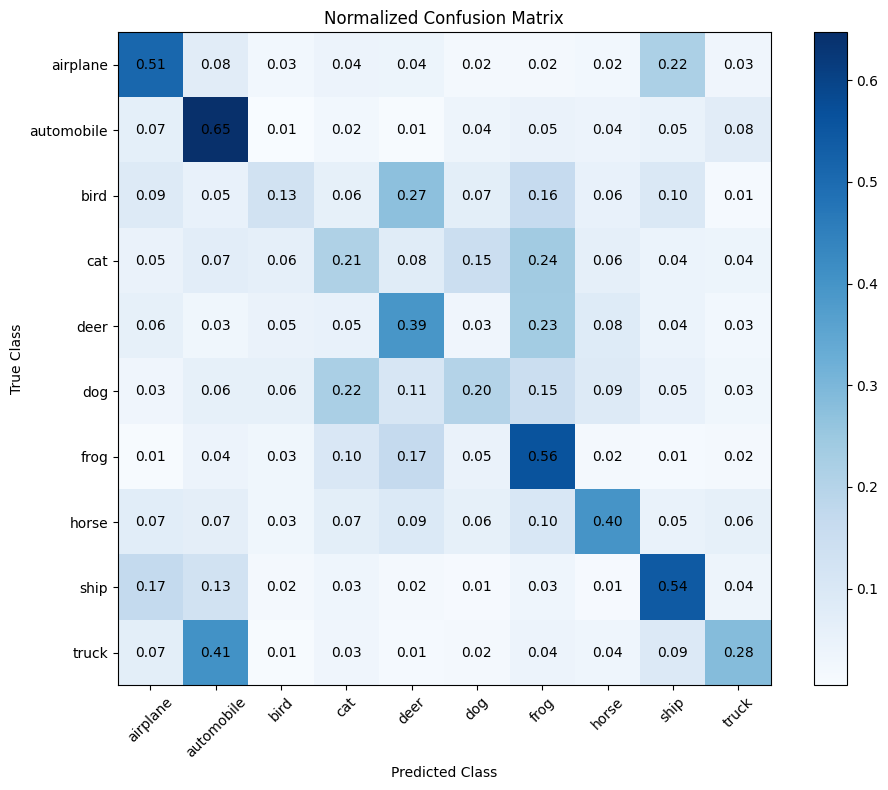

In [109]:

from sklearn.metrics import confusion_matrix

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

y_true = np.array(y_clean_test).reshape(-1)

predictions = model.predict(x_clean_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(10)
)

class_accuracy = cm.diagonal() / cm.sum(axis=1) * 100

print("Class-wise Accuracy:")
for i in range(10):
    print(class_names[i], ":", round(class_accuracy[i], 2), "%")

cm_normalized = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(10),
    normalize="true"
)

plt.figure(figsize=(10, 8))
plt.imshow(cm_normalized, cmap="Blues")
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, f"{cm_normalized[i, j]:.2f}",
            ha="center", va="center"
        )

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()


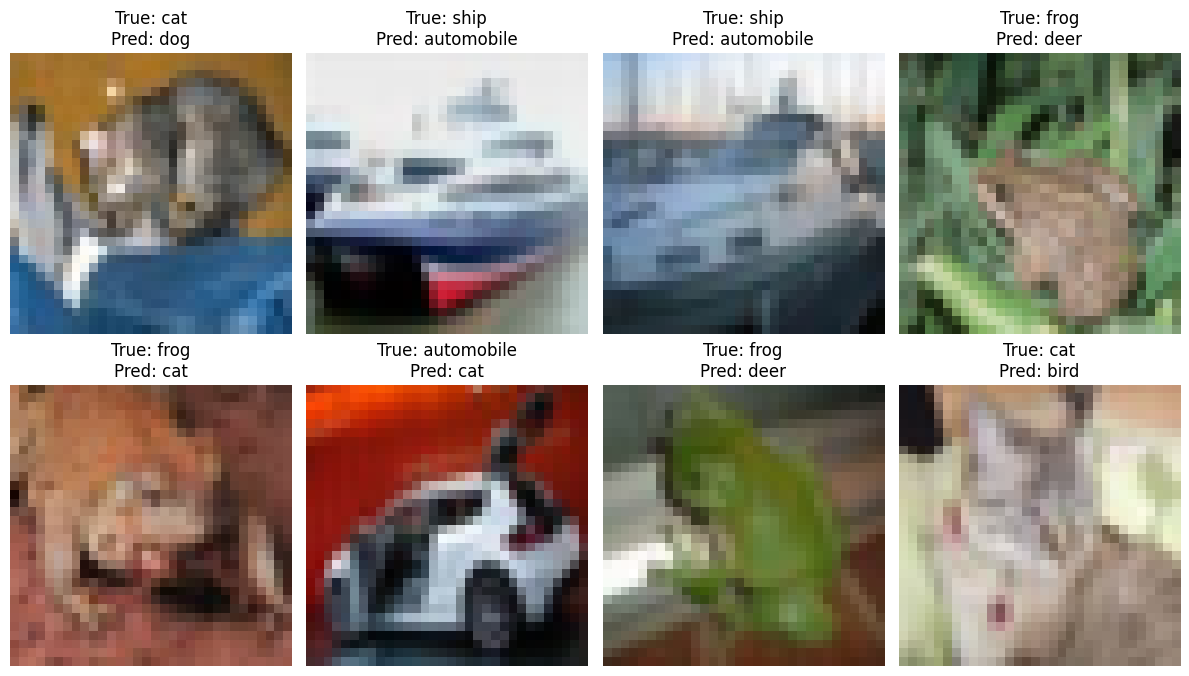

In [110]:
wrong = np.where(y_true != y_pred)[0]

plt.figure(figsize=(12, 7))

for i in range(8):
    index = wrong[i]

    plt.subplot(2, 4, i + 1)
    plt.imshow(x_clean_test[index])

    plt.title(
        "True: " + class_names[y_true[index]] +
        "\nPred: " + class_names[y_pred[index]]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [111]:
np.random.seed(42)

x_hidden = np.array(x_clean_test).copy()
for i in range(len(x_hidden)):
    if np.random.rand() < 0.2:
        x_hidden[i] = np.repeat(
            np.mean(x_hidden[i], axis=2, keepdims=True),
            3,
            axis=2
        )

print("Hidden test shape:", x_hidden.shape)

clean_predictions = model.predict(
    x_clean_test, verbose=0
)
clean_pred = np.argmax(clean_predictions, axis=1)
hidden_predictions = model.predict(
    x_hidden, verbose=0
)
hidden_pred = np.argmax(hidden_predictions, axis=1)

y_true = np.array(y_clean_test).reshape(-1)

clean_accuracy = np.mean(clean_pred == y_true)
hidden_accuracy = np.mean(hidden_pred == y_true)

print("Clean Test Accuracy:", round(clean_accuracy * 100, 2), "%")
print("Hidden Corruption Accuracy:", round(hidden_accuracy * 100, 2), "%")

difference = (clean_accuracy - hidden_accuracy) * 100

print("Accuracy Drop:", round(difference, 2), "percentage points")

if hidden_accuracy >= clean_accuracy:
    print("The model maintained its accuracy under grayscale corruption.")
else:
    print("The model's accuracy decreased under grayscale corruption.")


Hidden test shape: (10000, 32, 32, 3)
Clean Test Accuracy: 38.76 %
Hidden Corruption Accuracy: 35.58 %
Accuracy Drop: 3.18 percentage points
The model's accuracy decreased under grayscale corruption.


The model showed some generalization to the unseen grayscale corruption, but its performance decreased. The clean test accuracy was 38.76%, while the hidden-corruption accuracy was 35.48%, a drop of 3.18 percentage points. This indicates that the model can still classify some images when color information is removed, but its robustness to grayscale images is limited. Since grayscale augmentation was not included during training, the model may have relied partly on color features for classification.